# 02 Train
Fine-tune BART-base to write each abstract's human TLDR, using the 1,992 training abstracts only (no validation set, no checkpoints). The loss is cross-entropy between the model's predicted words and the human TLDR's words. The final model is saved once.

Reads `data/processed/train.jsonl`. Writes `outputs/model/` and `outputs/train_log.json`.

In [1]:
import json, math, os, shutil, time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch, transformers, yaml
from tqdm.auto import tqdm
from transformers import (AutoModelForSeq2SeqLM, AutoTokenizer, DataCollatorForSeq2Seq, Seq2SeqTrainer,
                          Seq2SeqTrainingArguments, TrainerCallback, set_seed)
from transformers.trainer_callback import PrinterCallback

if Path.cwd().name == "notebooks":
    os.chdir("..")                      # run everything from the repo root
ROOT = Path.cwd()
CFG = yaml.safe_load((ROOT / "configs" / "config.yaml").read_text())
D, T, SEED = CFG["data"], CFG["train"], CFG["seed"]
MODEL_DIR = ROOT / "outputs" / "model"
RETRAIN = False                         

if torch.cuda.is_available():
    gpu = torch.cuda.get_device_name(0)
    vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    precision = "bf16" if torch.cuda.get_device_capability(0)[0] >= 8 else "fp16"
else:
    gpu, vram, precision = "CPU (training will take hours)", 0, "fp32"
    if shutil.which("nvidia-smi"):
        print("WARNING: an NVIDIA GPU is present but this torch build is CPU-only. See the README.")
BS = 8 if (vram == 0 or vram >= 8) else (4 if vram >= 5 else 2)
GA = T["effective_batch"] // BS
print(f"torch {torch.__version__} | transformers {transformers.__version__} | {gpu} | {precision} | "
      f"batch {BS} x accumulation {GA} = {BS * GA}")

torch 2.7.1+cu126 | transformers 4.57.6 | NVIDIA GeForce GTX 1050 Ti | fp16 | batch 2 x accumulation 8 = 16


## Data

In [2]:
train = pd.read_json(ROOT / "data" / "processed" / "train.jsonl", orient="records", lines=True, dtype=False)
assert len(train) == D["sizes"]["train"], "run 01_data first"

tok = AutoTokenizer.from_pretrained(T["model"])
enc = tok(train.abstract.tolist(), max_length=D["max_source_len"], truncation=True)
labels = tok(text_target=[t[0] for t in train.human_tldrs], max_length=D["max_target_len"], truncation=True)["input_ids"]
train_ds = [{"input_ids": i, "attention_mask": m, "labels": l}
            for i, m, l in zip(enc["input_ids"], enc["attention_mask"], labels)]
print(len(train_ds), "training examples")
print("abstract:", tok.decode(train_ds[0]["input_ids"][:30], skip_special_tokens=True), "...")
print("TLDR:    ", tok.decode(train_ds[0]["labels"], skip_special_tokens=True))

1992 training examples
abstract: Due to the success of deep learning to solving a variety of challenging machine learning tasks, there is a rising interest in understanding loss functions for training neural ...
TLDR:     We provide necessary and sufficient analytical forms for the critical points of the square loss functions for various neural networks, and exploit the analytical forms to characterize the landscape properties for the loss functions of these neural networks.


## Train
A progress bar, plus a loss line every 20 steps. Nothing is saved until training finishes.

In [4]:
class TrainLog(TrainerCallback):
    """Progress bar and one loss line every 20 steps."""
    def on_train_begin(self, args, state, control, **kw):
        self.bar = tqdm(total=state.max_steps, desc="training")
    def on_step_end(self, args, state, control, **kw):
        self.bar.update(1)
    def on_log(self, args, state, control, logs=None, **kw):
        if logs and "loss" in logs:
            self.bar.write(f"step {state.global_step:>5} | epoch {logs.get('epoch', 0):.2f} | train loss {logs['loss']:.4f}")
    def on_train_end(self, args, state, control, **kw):
        self.bar.close()

def train_model():
    set_seed(SEED)
    total_steps = math.ceil(len(train_ds) / (BS * GA)) * T["epochs"]
    model = AutoModelForSeq2SeqLM.from_pretrained(T["model"])
    args = Seq2SeqTrainingArguments(
        output_dir=str(ROOT / "outputs" / "trainer_tmp"), num_train_epochs=T["epochs"],
        per_device_train_batch_size=BS, gradient_accumulation_steps=GA,
        learning_rate=T["lr"], weight_decay=T["weight_decay"],
        warmup_steps=int(T["warmup_ratio"] * total_steps),      
        eval_strategy="no", save_strategy="no", logging_steps=20, disable_tqdm=True,
        seed=SEED, data_seed=SEED, bf16=precision == "bf16", fp16=precision == "fp16", report_to="none")
    
    trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=train_ds,
                             data_collator=DataCollatorForSeq2Seq(tok, model=model),
                             processing_class=tok, callbacks=[TrainLog()])
    trainer.remove_callback(PrinterCallback)        
    # Without this, transformers 5.x does not divide BART's loss by the gradient-accumulation steps
    # and the logged loss comes out several times too large.
    trainer.model_accepts_loss_kwargs = False
    t0 = time.time()
    trainer.train()
    trainer.save_model(str(MODEL_DIR)); tok.save_pretrained(str(MODEL_DIR))
    (ROOT / "outputs" / "train_log.json").write_text(json.dumps(trainer.state.log_history, indent=2))
    print(f"finished in {(time.time() - t0) / 60:.1f} min, saved to {MODEL_DIR}")

if (MODEL_DIR / "config.json").exists() and not RETRAIN:
    print("outputs/model already exists, so training is skipped. Set RETRAIN = True to train again.")
else:
    train_model()

training:   0%|          | 0/625 [00:00<?, ?it/s]

step    20 | epoch 0.16 | train loss 3.8151
step    40 | epoch 0.32 | train loss 3.0836
step    60 | epoch 0.48 | train loss 2.9003
step    80 | epoch 0.64 | train loss 2.8814
step   100 | epoch 0.80 | train loss 2.8054
step   120 | epoch 0.96 | train loss 2.8825
step   140 | epoch 1.12 | train loss 2.5482
step   160 | epoch 1.28 | train loss 2.5792
step   180 | epoch 1.44 | train loss 2.6332
step   200 | epoch 1.60 | train loss 2.5215
step   220 | epoch 1.76 | train loss 2.5251
step   240 | epoch 1.92 | train loss 2.5604
step   260 | epoch 2.08 | train loss 2.4515
step   280 | epoch 2.24 | train loss 2.4192
step   300 | epoch 2.40 | train loss 2.3608
step   320 | epoch 2.56 | train loss 2.2747
step   340 | epoch 2.72 | train loss 2.2786
step   360 | epoch 2.88 | train loss 2.4046
step   380 | epoch 3.04 | train loss 2.3427
step   400 | epoch 3.20 | train loss 2.1609
step   420 | epoch 3.36 | train loss 2.1209
step   440 | epoch 3.52 | train loss 2.2764
step   460 | epoch 3.68 | train 

c:\Users\SAM\Documents\Repositories\csc173-midterm\.venv\Lib\site-packages\transformers\modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'early_stopping': True, 'num_beams': 4, 'no_repeat_ngram_size': 3, 'forced_bos_token_id': 0}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(


finished in 179.1 min, saved to c:\Users\SAM\Documents\Repositories\csc173-midterm\outputs\model


## Loss curve
The loss should fall from about 3-4 to about 2.

training loss: 3.82 -> 2.19


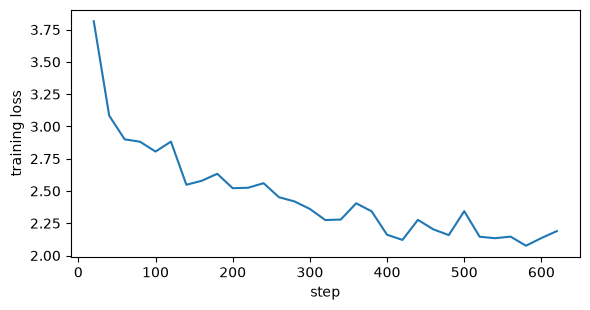

In [5]:
log = pd.DataFrame(json.loads((ROOT / "outputs" / "train_log.json").read_text())).dropna(subset=["loss"])
print(f"training loss: {log.loss.iloc[0]:.2f} -> {log.loss.iloc[-1]:.2f}")
if log.loss.iloc[-1] > 8:
    print("WARNING: far above the usual ~2. The loss is probably not divided by gradient accumulation.")
plt.figure(figsize=(6, 3.2)); plt.plot(log.step, log.loss)
plt.xlabel("step"); plt.ylabel("training loss"); plt.tight_layout(); plt.show()